# Case study 2 — Modi / Indian-election sentiment classification

The evaluation the original coursework was missing: a majority-class baseline,
repeated stratified cross-validation, macro-F1 (labels are imbalanced), a
stratified held-out confusion matrix and a real error analysis.

Executed end-to-end; every number below is produced by this notebook.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
print("repo root:", ROOT)


repo root: /home/heisenberg/portfolio-rework/repos/indonesian-tweet-sentiment-analysis


In [2]:
import pandas as pd
from functools import partial
from sklearn.metrics import f1_score
from idtweets import evaluation, modelling
from idtweets.cases import load_case_module
from idtweets.modelling import build_pipeline, default_estimators

case = load_case_module('modi-election', 'modi_election_sentiment.py')

## Data preparation

Encoding repair → drop rows with contact PII → English-aware preprocessing →
drop exact duplicates. Every removal is counted.

In [3]:
df, audit = case.prepare_dataset()
for k, v in audit.items():
    print(f'{k:26s}: {v if k != "pii_hits" else str(len(v)) + " row(s)" }')

rows_loaded               : 5324
dropped_missing_text      : 1
rows_with_mojibake        : 595
pii_rows_dropped          : 5
pii_hits                  : 5 row(s)
rows_empty_after_clean    : 3
duplicate_rows_dropped    : 84
rows_final                : 5232
class_counts              : {'negative': 1158, 'neutral': 1855, 'positive': 2219}


In [4]:
df.head(3)[['text', 'clean', 'category']]

,text,clean,category
0,"when modi promised ""minimum government maximum...",modi promised minimum government maximum gover...,-1
1,talk all the nonsense and continue all the dra...,talk nonsense continue drama vote modi,0
2,what did just say vote for modi welcome bjp t...,say vote modi welcome bjp told rahul main camp...,1


In [5]:
case.label_distribution(df)

,category,label_name,count,share
0,-1,negative,1158,0.2213
1,0,neutral,1855,0.3545
2,1,positive,2219,0.4241


### Why accuracy alone would be misleading

In [6]:
print(case.class_weight_note(df))

majority class positive = 42.4% of rows -> a model that always predicts it scores 42.4% accuracy but only macro-F1 0.199 (one class F1, two classes 0).


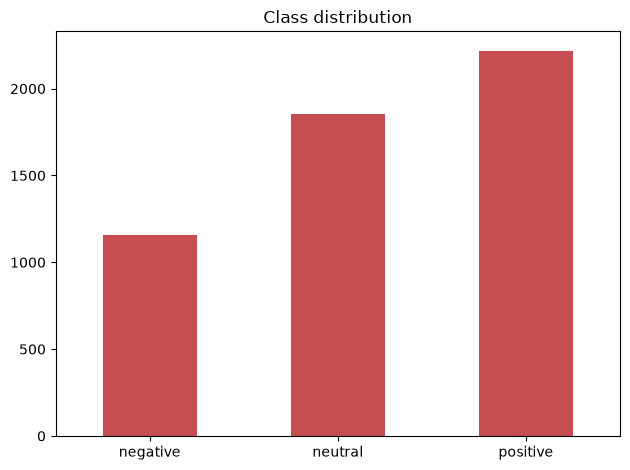

In [7]:
import matplotlib.pyplot as plt
from idtweets.io import FIGURES_DIR
dist = case.label_distribution(df)
ax = dist.plot.bar(x='label_name', y='count', legend=False, rot=0, color='#C44E52')
ax.set_title('Class distribution'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

## Model comparison — repeated stratified 5×3 cross-validation

15 fits per model. TF-IDF sits inside the pipeline, so it is refit on each fold
and the test fold's vocabulary never leaks into training.

In [8]:
table, results = case.run_comparison(df, n_splits=5, n_repeats=3)
table

,model,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std,fit_seconds
0,linear_svc,0.7343,0.0124,0.7198,0.0119,0.7330,0.0122,1.235
1,logistic_regression,0.7297,0.0125,0.7158,0.0126,0.7293,0.0122,119.554
2,naive_bayes,0.6243,0.0136,0.5773,0.0149,0.6045,0.0145,1.276
3,majority_baseline,0.4241,0.0004,0.1985,0.0001,0.2526,0.0004,1.335


In [9]:
print(f"Best macro-F1 beats the majority baseline by {case.macro_f1_gap(table):+.4f}")
for r in results.values():
    print(f'  {r.name:20s} macro-F1 {r.macro_f1_mean:.4f} +/- {r.macro_f1_std:.4f}')

Best macro-F1 beats the majority baseline by +0.5213
  majority_baseline    macro-F1 0.1985 +/- 0.0001
  naive_bayes          macro-F1 0.5773 +/- 0.0149
  logistic_regression  macro-F1 0.7158 +/- 0.0126
  linear_svc           macro-F1 0.7198 +/- 0.0119


## Held-out evaluation

Stratified 80/20 split, best CV model, with a bootstrap CI on macro-F1.

In [10]:
Xtr, Xte, ytr, yte = modelling.holdout_split(df['clean'], df['category'], test_size=0.2)
best_name = table.iloc[0]['model']
pipe = build_pipeline(default_estimators()[best_name]).fit(Xtr, ytr)
preds = pipe.predict(Xte)
metrics = evaluation.classification_metrics(yte, preds)
lo, hi = case.bootstrap_ci(yte, preds, partial(f1_score, average='macro'), n_boot=1000)
print('model:', best_name)
for k, v in metrics.items():
    print(f'  {k:12s}: {v:.4f}')
print(f'  macro-F1 95% CI: [{lo:.4f}, {hi:.4f}]')

model: linear_svc
  accuracy    : 0.7163
  macro_f1    : 0.7039
  weighted_f1 : 0.7154
  cohen_kappa : 0.5587
  macro-F1 95% CI: [0.6760, 0.7321]


In [11]:
evaluation.report_frame(yte, preds, label_names=case.LABEL_NAMES)

,label,label_name,precision,recall,f1,support
0,-1,negative,0.6714,0.6078,0.6380,232
1,0,neutral,0.7089,0.7547,0.7311,371
2,1,positive,0.7443,0.7410,0.7427,444


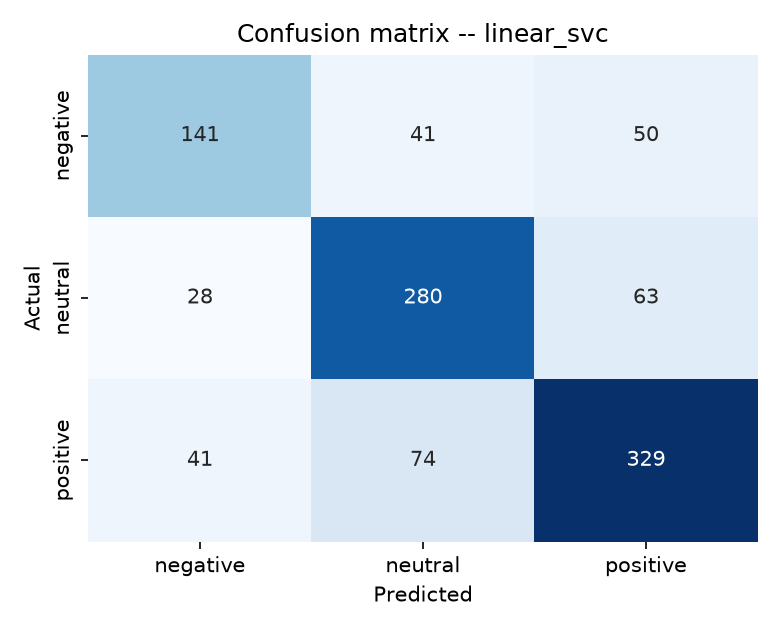

In [12]:
evaluation.plot_confusion(yte, preds, labels=[-1, 0, 1],
    label_names=case.LABEL_NAMES, title=f'Confusion matrix -- {best_name}',
    out_path=FIGURES_DIR / 'notebook_confusion.png');
from IPython.display import Image
Image(str(FIGURES_DIR / 'notebook_confusion.png'))

## Error analysis — real misclassified tweets

In [13]:
err = evaluation.error_analysis(Xte.reset_index(drop=True), yte.reset_index(drop=True),
    preds, label_names=case.LABEL_NAMES, n_per_class=6)
err[['true_name', 'pred_name', 'text']].assign(
    text=lambda d: d['text'].str.slice(0, 120))

,true_name,pred_name,text
0,neutral,positive,ways adani project stands gain sez status
1,neutral,negative,went tag celebrities ask respective fans vote ...
2,negative,neutral,pls dont beg tagging tat neeed something concr...
3,neutral,positive,modi bjp rss rule narrative responsibility opp...
4,negative,neutral,trying say modi afraid vendetta charge opposit...
5,neutral,positive,gathbandhan agenda defeat modi development mod...
6,neutral,negative,council patroninchief ramesh kumar vankwani su...
7,positive,negative,compared experienced modi led bjp rule past ye...
8,neutral,positive,modi govt provided lpg connections ujjwala yoj...
9,positive,neutral,larger blame increasing pollution congestion d...


In [14]:
err['direction'] = err['true_name'] + ' -> ' + err['pred_name']
err['direction'].value_counts().to_frame('errors_in_held_out_fold')

,errors_in_held_out_fold
direction,
neutral -> positive,4
negative -> neutral,4
positive -> negative,3
positive -> neutral,3
neutral -> negative,2
negative -> positive,2


## What the model actually keyed on

In [15]:
lr = build_pipeline(default_estimators()['logistic_regression']).fit(Xtr, ytr)
top = evaluation.top_features_per_class(lr, top_n=12)
for c in sorted(top['class'].unique()):
    print(case.LABEL_NAMES[c].upper() + ':')
    print('   ', ', '.join(top[top['class'] == c]['term'][:12]))
    print()

NEGATIVE:
    poor, fake, hate, corrupt, failed, wrong, bad, stupid, idiot, failure, due, game

NEUTRAL:
    modi, another, governor, lose, literally, terrorism, islamic, attention, airline, question modi, like modi, father

POSITIVE:
    good, best, first, better, new, great, many, right, win, true, much, wants



## Takeaways

* The corpus is small (5,232 usable rows after cleaning) and the label
  distribution is imbalanced, so **macro-F1**, not accuracy, is the number to
  quote — and a majority-class predictor is quoted next to it.
* The three real classifiers land close together; the notebook reports the
  standard deviation across folds rather than pretending the top row is a
  decisive winner.
* Errors concentrate on the neutral/positive boundary, where short tweets with
  no explicit sentiment cue are genuinely ambiguous — see the quoted rows above.
* The original coursework's single 0.63 accuracy figure was not wrong so much as
  uninterpretable: without a baseline and without per-class metrics, a reader
  cannot tell whether 0.63 is good.